## Importing required libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("charts", exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"

## loading the cleaned data

In [3]:
c = "cleaned/"
orders      = pd.read_csv(c + "orders.csv",      parse_dates=["order_date", "delivered_date"])
order_items = pd.read_csv(c + "order_items.csv")
customers   = pd.read_csv(c + "customers.csv",   parse_dates=["registration_date", "last_login_date"])
payments    = pd.read_csv(c + "payments.csv",    parse_dates=["payment_date", "refund_date"])
returns     = pd.read_csv(c + "returns.csv",     parse_dates=["return_date", "refund_date"])
products    = pd.read_csv(c + "products.csv")

orders["month"] = orders["order_date"].dt.to_period("M")
orders.shape

(50000, 20)

## Chart 1, monthly order volume

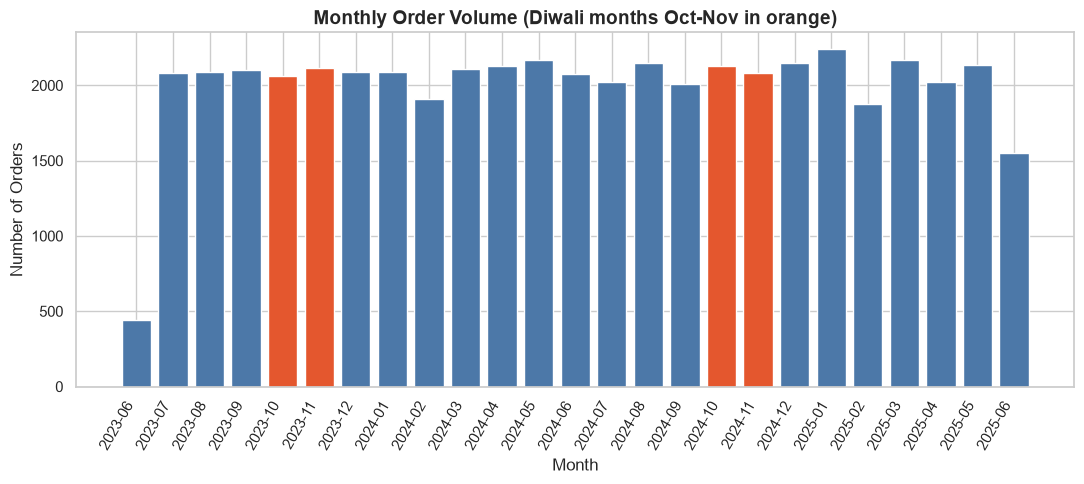

In [14]:
monthly_orders = orders.groupby("month").size()

colors = ["#E4572E" if m.month in (10, 11) else "#4C78A8" for m in monthly_orders.index]

fig, ax = plt.subplots()
ax.bar(monthly_orders.index.astype(str), monthly_orders.values, color=colors)
ax.set_title("Monthly Order Volume (Diwali months Oct-Nov in orange)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Orders")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.savefig("charts/01_monthly_orders.png", dpi=150)
plt.show()


**Observation:** Orders stay between about 2,000 and 2,200 every month, and the Diwali months (Oct and Nov, in orange) are no higher than the rest, so there is no festive spike. Jun 2023 (444 orders) and Jun 2025 are low only because the data starts on 24 Jun 2023 and ends on 23 Jun 2025. February is the lowest full month in both years (about 1,900 orders) because it has fewer days.

## Chart 2: Monthly GMV (year over year)

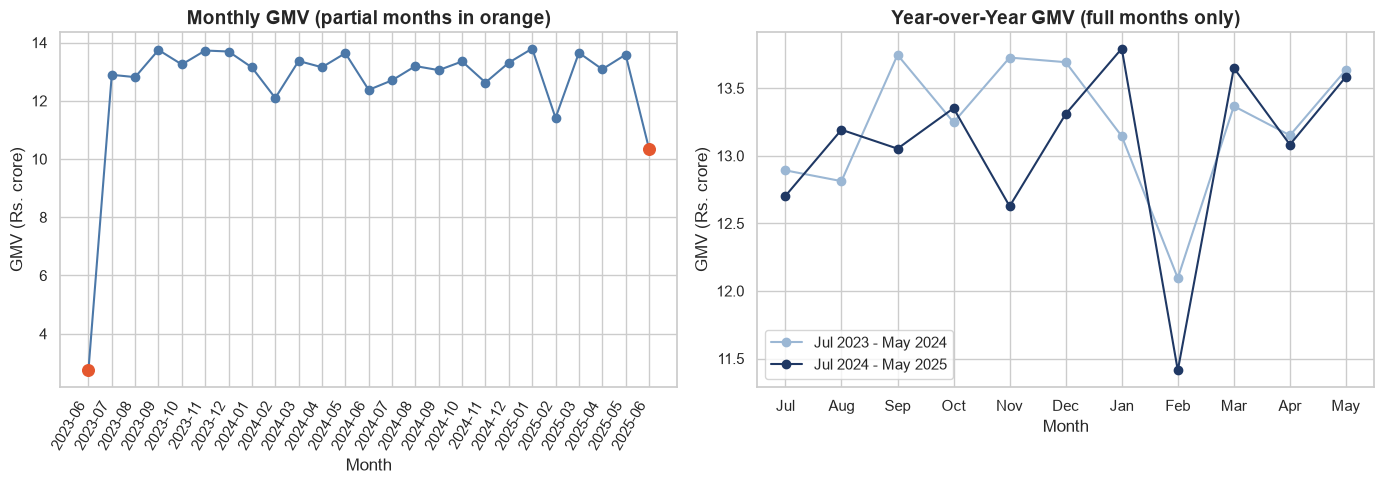

YoY GMV growth (Jul-May): -1.2%


In [15]:
gmv = orders.groupby("month")["final_amount"].sum() / 1e7   # in crore
partial = {pd.Period("2023-06"), pd.Period("2025-06")}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: full 25-month timeline, partial months highlighted
ax = axes[0]
ax.plot(gmv.index.astype(str), gmv.values, marker="o", color="#4C78A8")
for m in partial:
    ax.scatter(str(m), gmv[m], color="#E4572E", zorder=5, s=70)
ax.set_title("Monthly GMV (partial months in orange)")
ax.set_xlabel("Month"); ax.set_ylabel("GMV (Rs. crore)")
ax.tick_params(axis="x", rotation=60)
for lbl in ax.get_xticklabels(): lbl.set_ha("right")

# Right: year-over-year on full months only (Jul to May)
full = gmv.drop(list(partial))
yr1 = full[(full.index >= "2023-07") & (full.index <= "2024-05")]
yr2 = full[(full.index >= "2024-07") & (full.index <= "2025-05")]
labels = [m.strftime("%b") for m in yr1.index]

ax = axes[1]
ax.plot(labels, yr1.values, marker="o", label="Jul 2023 - May 2024", color="#9BB7D4")
ax.plot(labels, yr2.values, marker="o", label="Jul 2024 - May 2025", color="#1F3864")
ax.set_title("Year-over-Year GMV (full months only)")
ax.set_xlabel("Month"); ax.set_ylabel("GMV (Rs. crore)")
ax.legend()

plt.tight_layout()
plt.savefig("charts/02_monthly_gmv.png", dpi=150)
plt.show()

growth = (yr2.sum() / yr1.sum() - 1) * 100
print(f"YoY GMV growth (Jul-May): {growth:.1f}%")


**Observation:** Monthly GMV stays at about Rs. 12 to 14 crore. Over the same 11 full months (Jul to May), year 2 is 1.2% lower than year 1 (Rs. 143.8 crore vs Rs. 145.5 crore), so sales are flat, not growing. The right chart's y-axis does not start at zero, so the swings look larger than they are, and February is the weakest month in both years.

## Chart 3: Category revenue share

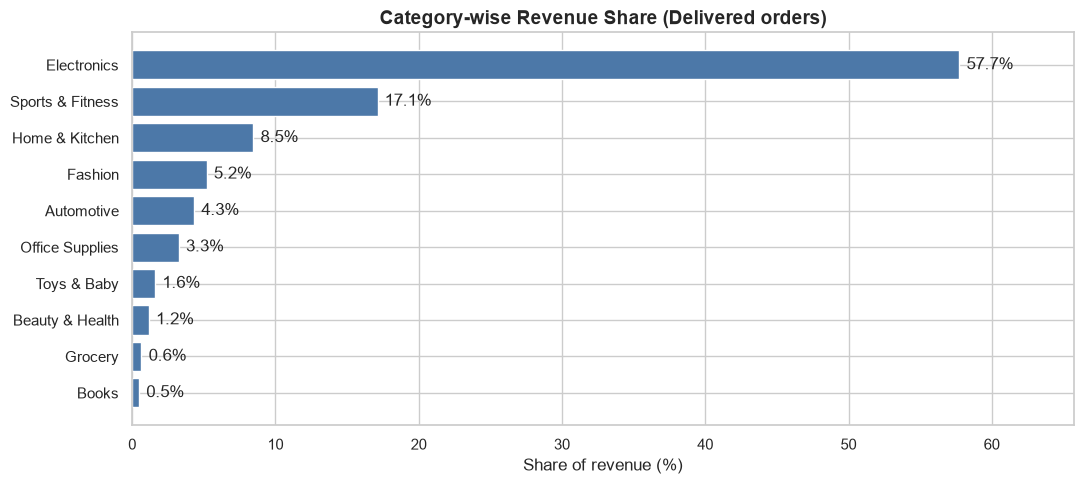

In [16]:
items = order_items.merge(orders[["order_id", "status"]], on="order_id", how="left")
rev = (items[items["status"] == "Delivered"]
       .groupby("category")["total_price"].sum().sort_values())
share = rev / rev.sum() * 100

fig, ax = plt.subplots()
bars = ax.barh(share.index, share.values, color="#4C78A8")
for b, v in zip(bars, share.values):
    ax.text(v + 0.5, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center")
ax.set_title("Category-wise Revenue Share (Delivered orders)")
ax.set_xlabel("Share of revenue (%)"); ax.set_ylabel("")
ax.set_xlim(0, share.max() + 8)
plt.tight_layout()
plt.savefig("charts/03_category_share.png", dpi=150)
plt.show()


**Observation:** Electronics earns 57.7% of delivered revenue, followed by Sports & Fitness (17.1%) and Home & Kitchen (8.5%), so the top three categories bring in about 83%. Electronics is close to the 60% concentration-risk line, while Books (0.5%), Grocery (0.6%) and Beauty & Health (1.2%) contribute the least. These figures cover about 91% of net revenue, because some delivered orders have no line items.

## Chart 4: Order status donut

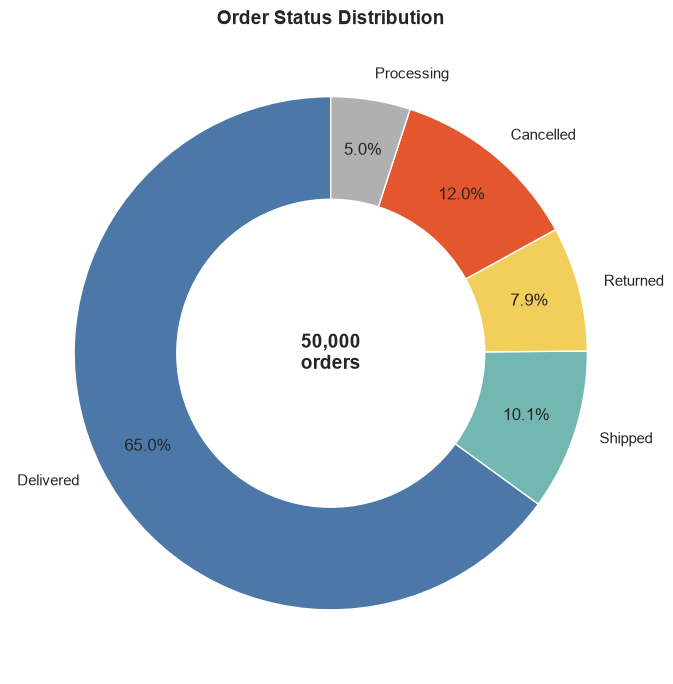

In [17]:
status = orders["status"].value_counts().reindex(
    ["Delivered", "Shipped", "Returned", "Cancelled", "Processing"])

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(status.values, labels=status.index, autopct="%1.1f%%",
       startangle=90, pctdistance=0.8,
       colors=["#4C78A8", "#72B7B2", "#F2CF5B", "#E4572E", "#B0B0B0"],
       wedgeprops=dict(width=0.4, edgecolor="white"))
ax.text(0, 0, f"{len(orders):,}\norders", ha="center", va="center",
        fontsize=14, fontweight="bold")
ax.set_title("Order Status Distribution")
plt.tight_layout()
plt.savefig("charts/04_order_status.png", dpi=150)
plt.show()


**Observation:** 65.0% of orders are Delivered, 12.0% Cancelled, 10.1% Shipped, 7.9% Returned and 5.0% Processing. The 12.0% cancellation rate is above the 10% target, which means about one order in eight is lost before delivery.

## Chart 5: Top 10 states by number of orders

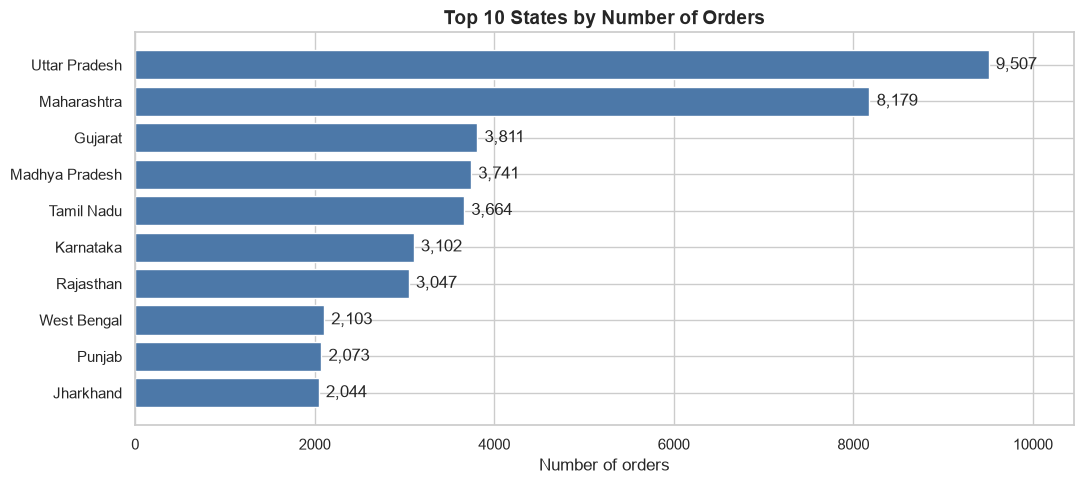

In [18]:
top_states = orders["state"].value_counts().head(10).sort_values()

fig, ax = plt.subplots()
bars = ax.barh(top_states.index, top_states.values, color="#4C78A8")
for b, v in zip(bars, top_states.values):
    ax.text(v + 80, b.get_y() + b.get_height() / 2, f"{v:,}", va="center")
ax.set_title("Top 10 States by Number of Orders")
ax.set_xlabel("Number of orders"); ax.set_ylabel("")
ax.set_xlim(0, top_states.max() * 1.1)
plt.tight_layout()
plt.savefig("charts/05_top_states.png", dpi=150)
plt.show()


**Observation:** Uttar Pradesh (9,507 orders) and Maharashtra (8,179) are the two biggest markets, together about 35% of all orders, and adding Gujarat (3,811) takes the top three to 43%. Orders come from 18 states, and the remaining states are far behind the leaders.

## Chart 6: Customer segment distribution

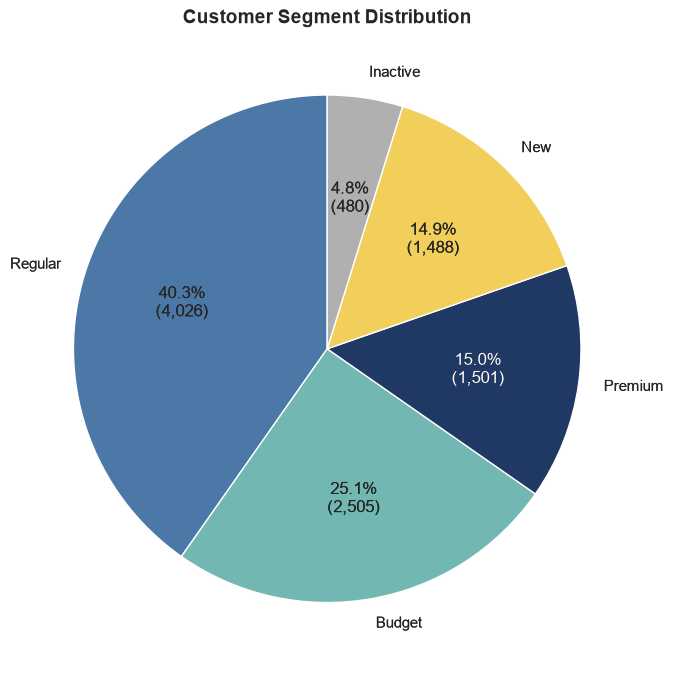

In [19]:
seg = customers["segment"].value_counts().reindex(
    ["Regular", "Budget", "Premium", "New", "Inactive"])

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(seg.values, labels=seg.index,
       autopct=lambda p: f"{p:.1f}%\n({p * seg.sum() / 100:,.0f})",
       startangle=90,
       colors=["#4C78A8", "#72B7B2", "#1F3864", "#F2CF5B", "#B0B0B0"],
       wedgeprops=dict(edgecolor="white"))
ax.set_title("Customer Segment Distribution")
wedges, texts, autotexts = ax.pie(seg.values, labels=seg.index,
       autopct=lambda p: f"{p:.1f}%\n({p * seg.sum() / 100:,.0f})",
       startangle=90,
       colors=["#4C78A8", "#72B7B2", "#1F3864", "#F2CF5B", "#B0B0B0"],
       wedgeprops=dict(edgecolor="white"))
autotexts[2].set_color("white")   # Premium slice is dark navy
plt.tight_layout()
plt.savefig("charts/06_segments.png", dpi=150)
plt.show()


**Observation:** Regular is the largest segment with 4,026 customers (40.3%), followed by Budget with 2,505 (25.1%), Premium with 1,501 (15.0%), New with 1,488 (14.9%) and Inactive with 480 (4.8%). These shares match the split expected in the data dictionary.

## Chart 7: Payment method usage

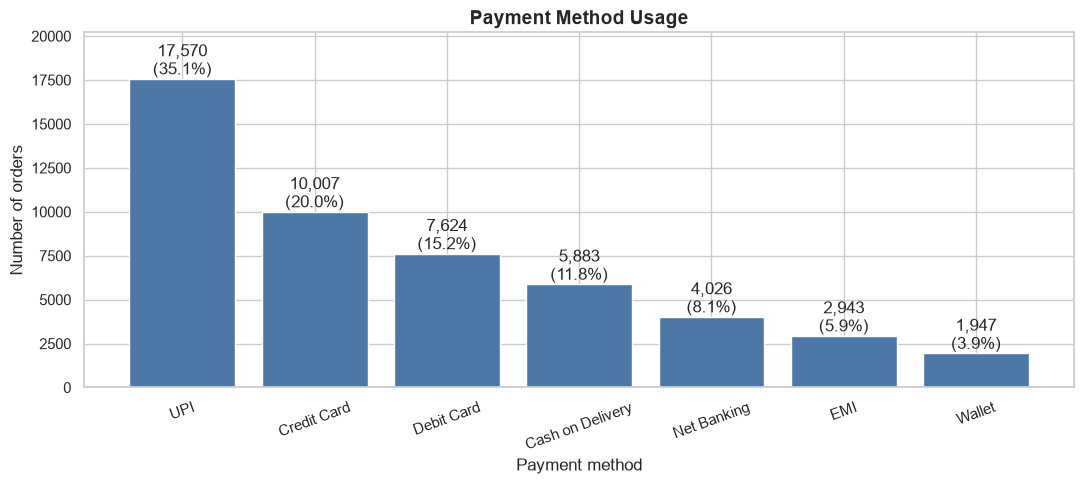

In [20]:
pm = orders["payment_method"].value_counts()

fig, ax = plt.subplots()
bars = ax.bar(pm.index, pm.values, color="#4C78A8")
for b, v in zip(bars, pm.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 250,
            f"{v:,}\n({v / len(orders) * 100:.1f}%)", ha="center")
ax.set_title("Payment Method Usage")
ax.set_xlabel("Payment method"); ax.set_ylabel("Number of orders")
ax.set_ylim(0, pm.max() * 1.15)
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("charts/07_payment_methods.png", dpi=150)
plt.show()


**Observation:** UPI is the most used payment method (35.1% of orders), followed by Credit Card (20.0%) and Debit Card (15.2%). Cash on Delivery is 11.8%, Net Banking 8.1%, EMI 5.9% and Wallet 3.9%, so digital payments dominate and COD is roughly one order in eight.

## Chart 8: Age distribution of customers

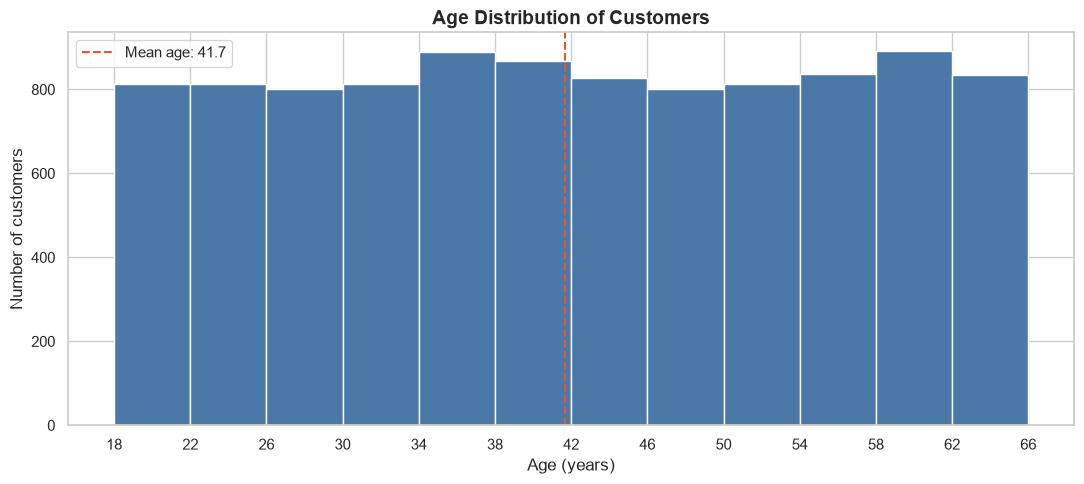

In [21]:
fig, ax = plt.subplots()
ax.hist(customers["age"], bins=np.arange(18, 67, 4), color="#4C78A8", edgecolor="white")
ax.axvline(customers["age"].mean(), color="#E4572E", linestyle="--",
           label=f"Mean age: {customers['age'].mean():.1f}")
ax.set_title("Age Distribution of Customers")
ax.set_xlabel("Age (years)"); ax.set_ylabel("Number of customers")
ax.set_xticks(np.arange(18, 67, 4))
ax.legend()
plt.tight_layout()
plt.savefig("charts/08_age_distribution.png", dpi=150)
plt.show()


**Observation:** Customers are aged 18 to 65, with a mean age of 41.7 and a median of 42. Every 4-year age band holds roughly 800 to 890 customers, so the distribution is very even and no single age group dominates.

## Chart 9: Return reasons

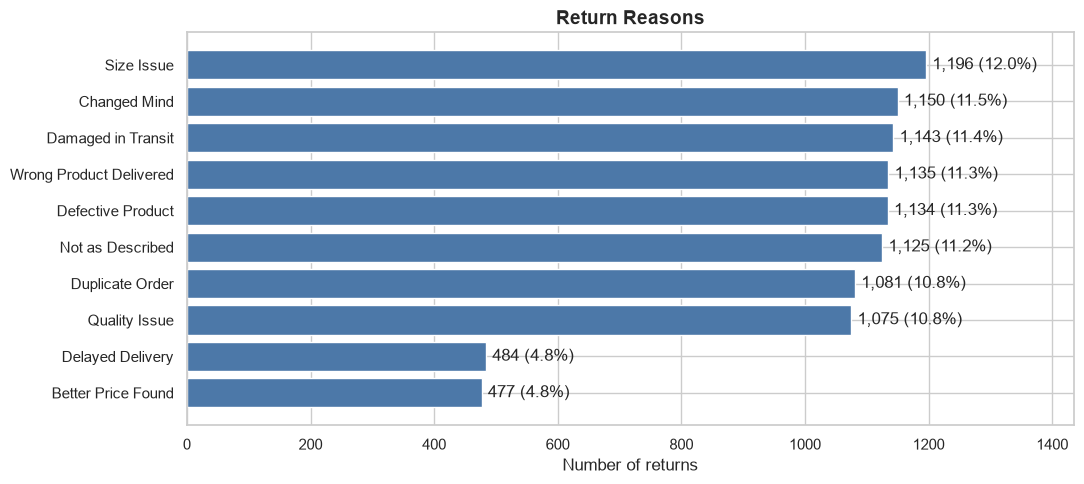

In [22]:
rr = returns["reason"].value_counts().sort_values()

fig, ax = plt.subplots()
bars = ax.barh(rr.index, rr.values, color="#4C78A8")
for b, v in zip(bars, rr.values):
    ax.text(v + 10, b.get_y() + b.get_height() / 2,
            f"{v:,} ({v / len(returns) * 100:.1f}%)", va="center")
ax.set_title("Return Reasons")
ax.set_xlabel("Number of returns"); ax.set_ylabel("")
ax.set_xlim(0, rr.max() * 1.2)
plt.tight_layout()
plt.savefig("charts/09_return_reasons.png", dpi=150)
plt.show()


**Observation:** Size Issue is the top return reason (1,196 returns, 12.0%), but the next seven reasons are almost the same (about 1,075 to 1,150 each), while Delayed Delivery (484) and Better Price Found (477) are about half as common. Damaged in Transit, Wrong Product Delivered, Defective Product, Not as Described and Quality Issue together account for about 5,600 returns (56%), which points to product and delivery quality as the main drivers.

## Chart 10: AOV by segment

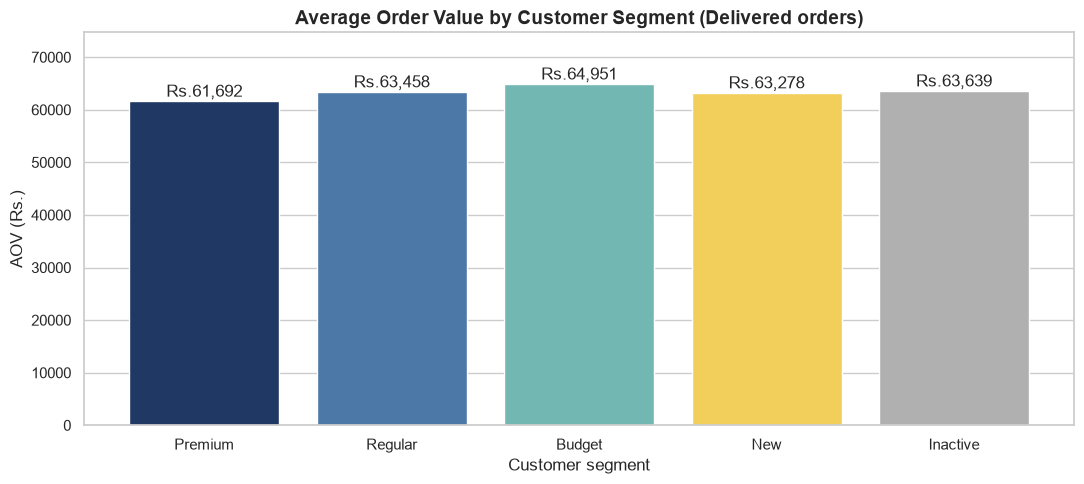

In [23]:
oc = orders.merge(customers[["customer_id", "segment"]], on="customer_id", how="left")
delivered = oc[oc["status"] == "Delivered"]

aov = (delivered.groupby("segment")["final_amount"].mean()
       .reindex(["Premium", "Regular", "Budget", "New", "Inactive"]))

fig, ax = plt.subplots()
bars = ax.bar(aov.index, aov.values,
              color=["#1F3864", "#4C78A8", "#72B7B2", "#F2CF5B", "#B0B0B0"])
for b, v in zip(bars, aov.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 800, f"Rs.{v:,.0f}", ha="center")
ax.set_title("Average Order Value by Customer Segment (Delivered orders)")
ax.set_xlabel("Customer segment"); ax.set_ylabel("AOV (Rs.)")
ax.set_ylim(0, aov.max() * 1.15)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig("charts/10_aov_segment.png", dpi=150)
plt.show()


**Observation:** Average order value is almost the same in every segment, between about Rs. 61,700 and Rs. 65,000 (overall Rs. 63,198). Premium customers (Rs. 61,692) do not spend more per order than Regular (Rs. 63,458) or Budget (Rs. 64,951) customers. Premium customers are more valuable because they order more often, about 8.6 orders on average against 5.7 for Regular, not because each order is bigger.

## Key Takeaways

1. **Stable but flat business.** About 2,100 orders and Rs. 13 crore GMV a month. Full-month GMV is 1.2% lower year over year, and there is no visible Diwali spike.
2. **Revenue is concentrated.** Electronics earns 57.7% of revenue, and the top 3 categories earn about 83%. Books, Grocery and Beauty & Health are each under 1.5%.
3. **Order outcomes need attention.** Only 65.0% of orders are delivered; 12.0% are cancelled (above the 10% target) and 7.9% are returned.
4. **Two states dominate.** Uttar Pradesh and Maharashtra give about 35% of all orders.
5. **Digital payments lead.** UPI is 35.1% of orders; Cash on Delivery is 11.8%.
6. **Customers are spread evenly across ages 18 to 65.** No single age group dominates.
7. **Premium customers do not spend more per order.** Their AOV (Rs. 61,692) is slightly below Regular (Rs. 63,458), so their value comes from order frequency.
8. **Returns are mostly quality and logistics issues.** About 56% of returns come from damaged, wrong, defective, not-as-described, or quality problems.